## Learning objectives

1. Understanding and interpreting the correlation between different features of a dataset.
2. Applying PCA on a real world dataset and understanding how much data is stored in which components.
3. Visualizing high dimensional data by first reducing it to two dimensions by using PCA and then plotting it.
4. Observing how the performance of a model varies with the number of principle components used.


Two of the uses of PCA are to visualize high dimensional datasets and improve the training speed of machine learning models. In this notebook, we will demonstrate how PCA helps us with both of these.

We will analyze the breast cancer dataset of sklearn. We will first load the dataset and split it into the training and test sets. Then, we will perform logistic regression on the training set and evaluate our model on the test set. Having done that, we will visualize and analyze correlations in the data. We would explore how PCA helps us compress the data and project it onto two dimensions so that we can plot it. Lastly, we will perform logistic regression on the compressed data and see how that stacks up against the performance of the model on the original data.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

%matplotlib inline

In [2]:
dat = datasets.load_breast_cancer() 
print(dat.DESCR)

.. _breast_cancer_dataset:

Breast cancer wisconsin (diagnostic) dataset
--------------------------------------------

**Data Set Characteristics:**

:Number of Instances: 569

:Number of Attributes: 30 numeric, predictive attributes and the class

:Attribute Information:
    - radius (mean of distances from center to points on the perimeter)
    - texture (standard deviation of gray-scale values)
    - perimeter
    - area
    - smoothness (local variation in radius lengths)
    - compactness (perimeter^2 / area - 1.0)
    - concavity (severity of concave portions of the contour)
    - concave points (number of concave portions of the contour)
    - symmetry
    - fractal dimension ("coastline approximation" - 1)

    The mean, standard error, and "worst" or largest (mean of the three
    worst/largest values) of these features were computed for each image,
    resulting in 30 features.  For instance, field 0 is Mean Radius, field
    10 is Radius SE, field 20 is Worst Radius.

    - 

In [6]:
df_all.columns

Index(['mean radius', 'mean texture', 'mean perimeter', 'mean area',
       'mean smoothness', 'mean compactness', 'mean concavity',
       'mean concave points', 'mean symmetry', 'mean fractal dimension',
       'radius error', 'texture error', 'perimeter error', 'area error',
       'smoothness error', 'compactness error', 'concavity error',
       'concave points error', 'symmetry error', 'fractal dimension error',
       'worst radius', 'worst texture', 'worst perimeter', 'worst area',
       'worst smoothness', 'worst compactness', 'worst concavity',
       'worst concave points', 'worst symmetry', 'worst fractal dimension'],
      dtype='object')

In [5]:
df_all = pd.DataFrame(dat.data, columns=dat.feature_names) 
df_all.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


### Creating Train and Test sets
In order to enable our model to make predictions on whether a tumour is malignant or benign, we need to train it from some data. However, to then evaluate the performance of our model, we need to check that it classifies unseen data correctly. Taht is why we split the data that we have into two sets - the training set and the test set. We train the parameters for the model by using the training set and then evaluate how good is the model using the test set. 

We take 70% of the samples into the training set and 30% into the test set, which is conventional for the size of this dataset.

In [10]:
TEST_SIZE_RATIO = 0.3

X = df_all 
y = pd.Series(list(dat['target'])) 

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = TEST_SIZE_RATIO, random_state=0)

# Normalizing the data
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)
print("X_train.shape, y_train.shape", X_train.shape, y_train.shape)
print("X_test.shape, y_test.shape", X_test.shape, y_test.shape)

X_train.shape, y_train.shape (398, 30) (398,)
X_test.shape, y_test.shape (171, 30) (171,)


### Logistic Regression
Logistic regression will be performed on unmodified data.
This technique classifies data into different classes i.e. classifying an image of a fruit as an orange or apple.

The classes are malignant (=0) and benign(=1).

A metric called the `f1 score` is used to assess how well the model predicts whether a tumor is malignant or benign and gives a numerical score. Higher scores indicate better predictions.



In [11]:
model = LogisticRegression(random_state=0).fit(X_train, y_train)
print("Training score: ", f1_score(y_train, model.predict(X_train)))
print("Testing score: ", f1_score(y_test, model.predict(X_test)))

Training score:  0.9920318725099602
Testing score:  0.981651376146789


#### Visualizing Correlation of the Features
Some features may be highly correlated to one another. Let's create a heatmap to visualize the correlation between features. 

Function correlation_matrix: X.shape, y.shape, yX.shape: (569, 30) (569,) (569, 31)



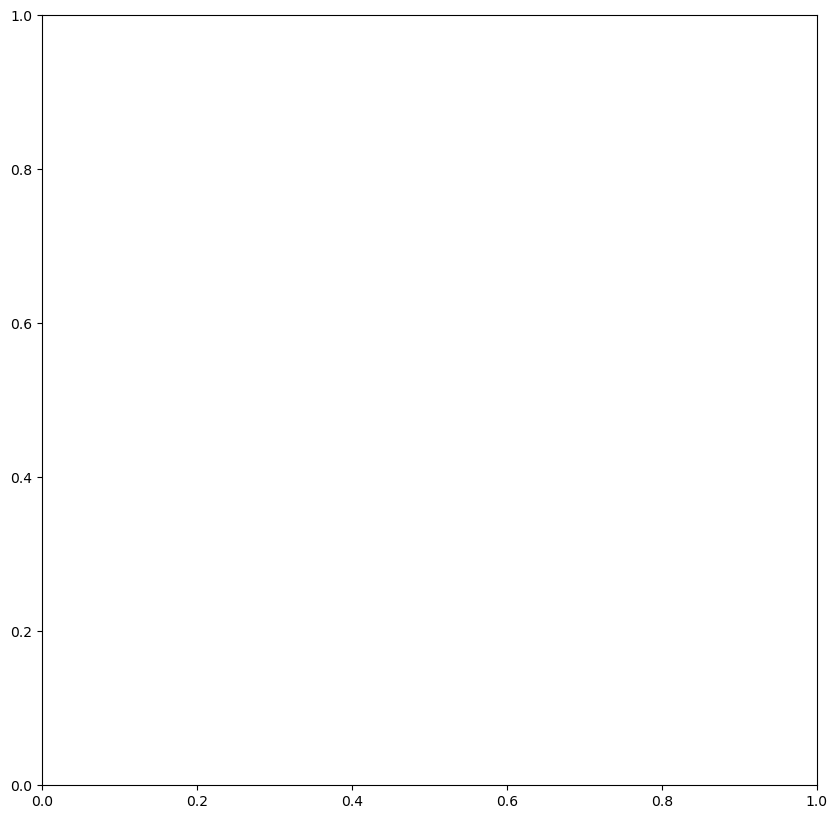

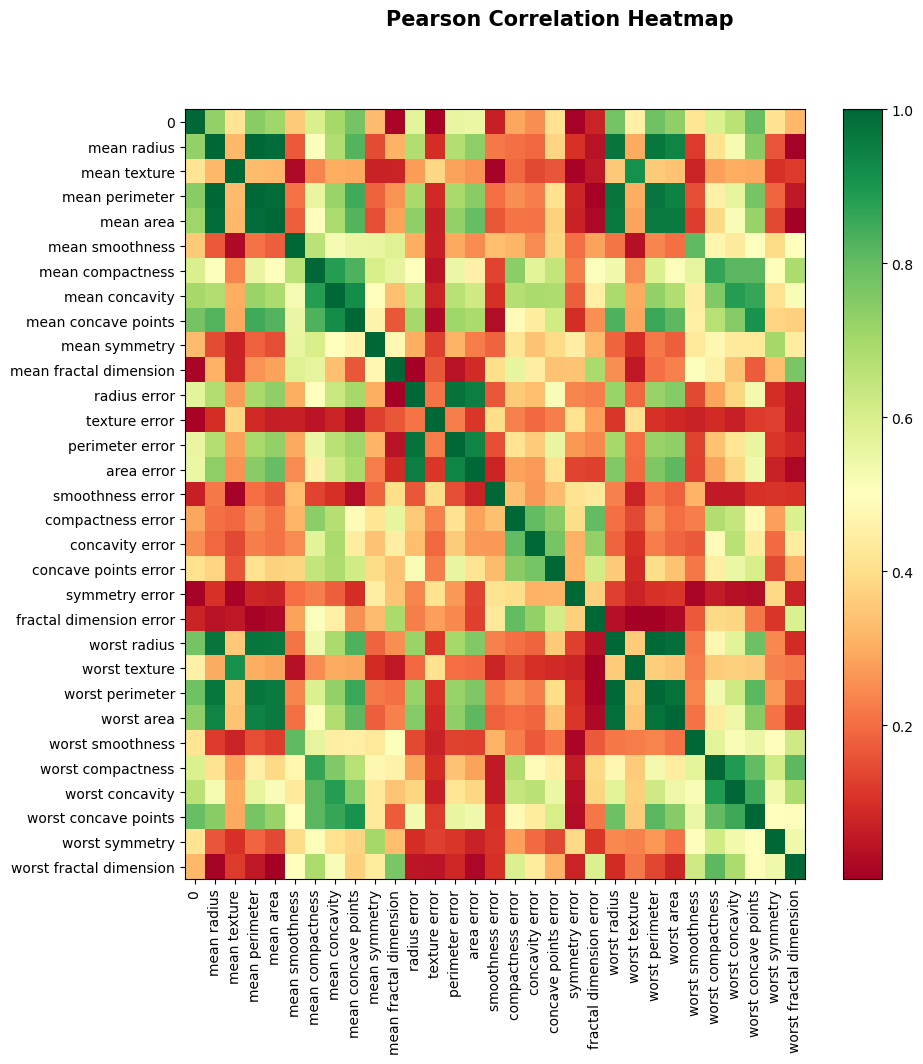

In [13]:
def correlation_matrix(y, X, is_plot=False):
    """ Calculate and plot the correlation symmetrical matrix
    Returns:
    yX - concatenated data
    yX_corr - correlation matrix, pearson correlation of values from -1 to +1
    """  
    yX = pd.concat([y, X], axis=1)
    yX - yX.rename(columns={0: 'TARGET'})
    print("Function correlation_matrix: X.shape, y.shape, yX.shape:", X.shape, y.shape, yX.shape)
    print()

    yX_corr = yX.corr(method='pearson')

    yX_abs_corr = np.abs(yX_corr)

    if is_plot:
        plt.figure(figsize=(10,10))
        plt.imshow(yX_abs_corr, cmap='RdYlGn', interpolation='none', aspect='auto')
        plt.colorbar()
        plt.xticks(range(len(yX_abs_corr)), yX_abs_corr.columns, rotation='vertical')
        plt.yticks(range(len(yX_abs_corr)), yX_abs_corr.columns);
        plt.suptitle('Pearson Correlation Heatmap', fontsize=15, fontweight='bold')
        plt.show()
    return yX, yX_corr,yX_abs_corr 

yX, yX_corr, yX_abs_corr = correlation_matrix(y,X,is_plot=True)

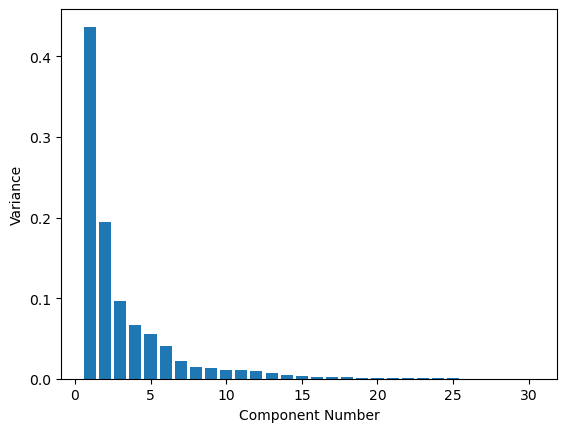

In [14]:
pca = PCA()
X_train_reduced = pca.fit_transform(X_train)
X_test_reduced = pca.transform(X_test)

plt.ylabel('Variance')
plt.xlabel('Component Number')
plt.bar(np.arange(30) + 1, pca.explained_variance_ratio_) 
plt.show()

In [15]:
print(pca.explained_variance_ratio_)

[4.36893153e-01 1.94151626e-01 9.66154484e-02 6.71661075e-02
 5.49883033e-02 4.01225718e-02 2.18306816e-02 1.48922601e-02
 1.37410827e-02 1.10137130e-02 1.04826288e-02 9.16214247e-03
 7.66306051e-03 5.14226331e-03 3.19635178e-03 2.51968451e-03
 1.92415148e-03 1.65844223e-03 1.49026749e-03 1.06777316e-03
 1.01725216e-03 8.48954816e-04 7.43492725e-04 5.81295611e-04
 5.44222785e-04 2.53545469e-04 2.14385701e-04 4.62967124e-05
 2.51158320e-05 3.72534805e-06]


### Visualizing the Data
One of the uses of PCA is that it lets us visualize high dimensional data.

PCA lets us project our original data into a two dimensional space. This lets us visualize the data by plotting it on a graph. Below, we will visualize the training set by performing PCA on it and only considering the first 2 components.

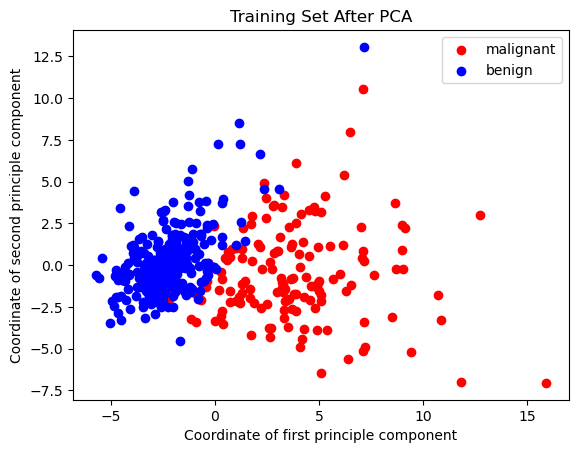

In [16]:
pca = PCA(n_components=2)
X_train_reduced = pca.fit_transform(X_train)
X_test_reduced = pca.transform(X_test)

X_train_reduced_malignant = np.array([x for x, y in zip(X_train_reduced, y_train) if y == 0])
X_train_reduced_benign = np.array([x for x, y in zip(X_train_reduced, y_train) if y == 1])

plt.scatter(*X_train_reduced_malignant.T, color='red')
plt.scatter(*X_train_reduced_benign.T, color='blue')
plt.title('Training Set After PCA')
plt.legend(['malignant', 'benign'])
plt.xlabel('Coordinate of first principle component')
plt.ylabel('Coordinate of second principle component')
plt.show()

### Performing Logistic Regression
We will now perform logistic regression again, but this time we will first perform PCA on the data and only consider the first 5 components.

In [21]:
pca = PCA(n_components=5)
X_train_reduced = pca.fit_transform(X_train)
X_test_reduced = pca.transform(X_test)

model = LogisticRegression(random_state=0).fit(X_train_reduced, y_train)
print("Training score: ", f1_score(y_train, model.predict(X_train_reduced)))
print("Testing score: ", f1_score(y_test, model.predict(X_test_reduced)))

Training score:  0.9859719438877755
Testing score:  0.9769585253456221


This time we get a test set score of 97.7%, which is only marginally worse than the original score of 98.17%. However, by using only one-sixth of the amount of data we had initially used, our model shall be trained much faster. While the effect might not be noticeable in this case, it can be huge in certain applications, where the models might have taken many days to train otherwise.

We encourage you to vary the value of n_components in the code above and see how the test set accuracy changes. In particular, notice that by using just a single component, we already get a score of 91.59%. Moreover, if we use 14 components, we get a score of 98.17%, which is equal to what we got for the original data, but uses less than half the number of features.

We plot the training score and test score against the number of components. Note that while the training score and test score generally increase with an increase in the number of components, this does not always have to hold. In practice, you need to experiment with different values of n_components and find out what works for the specific problem that you are trying to solve.

In [22]:
loadings = pd.DataFrame(
    pca.components_.T,
    index=dat.feature_names,
    columns=[f"PC{i+1}" for i in range(pca.n_components_)]
)
# how much of each component's variance each variable carries
# (each component is unit length, so these sum to 1 down a column)
contribution = loadings.pow(2)
summary = loadings.copy()
summary.insert(0, "PC1_abs", loadings["PC1"].abs())
summary = summary.sort_values("PC1_abs", ascending=False)
variance = pd.Series(
    pca.explained_variance_ratio_,
    index=[f"PC{i+1}" for i in range(pca.n_components_)],
    name="variance_explained"
)
summary

,PC1_abs,PC1,PC2,PC3,PC4,PC5
mean concave points,0.263651,0.263651,-0.030043,-0.015643,-0.051420,-0.043497
mean concavity,0.261180,0.261180,0.056321,0.016926,-0.013793,0.077073
worst concave points,0.252499,0.252499,-0.001780,-0.173641,-0.022194,0.043900
mean compactness,0.241720,0.241720,0.148399,-0.075560,-0.036005,0.005991
worst perimeter,0.237685,0.237685,-0.198437,-0.045478,-0.016289,0.006199
worst concavity,0.232876,0.232876,0.092327,-0.179822,0.050905,0.177110
worst radius,0.230372,0.230372,-0.214493,-0.045761,-0.015892,-0.002423
mean perimeter,0.229778,0.229778,-0.211640,-0.004253,-0.049049,0.030797
worst area,0.227031,0.227031,-0.214442,-0.006901,-0.011896,-0.027360
mean area,0.223599,0.223599,-0.225715,0.036823,-0.049377,0.000367


These are the variable loadings corresponding to each component and describe what the breast-cancer features represent. The weights can be read as which characteristics drive each component. The first component is a shared size-and-irregularity axis. Later components pick up characteristics taht do not move with that axis: boundary complexity. 

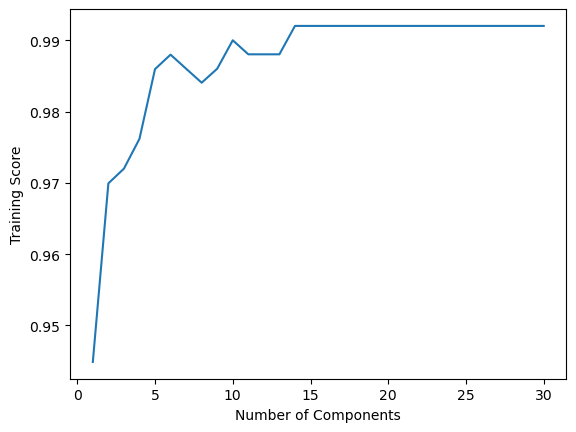

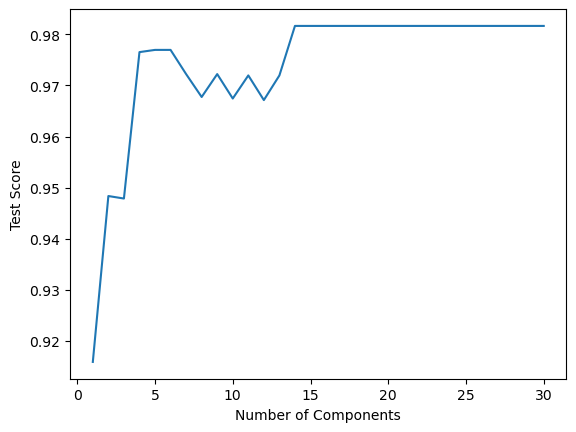

In [ ]:
X = np.arange(30) + 1
Y = []

for i in X:
    pca = PCA(n_components=i)
    X_train_reduced = pca.fit_transform(X_train)
    model = LogisticRegression(random_state=0).fit(X_train_reduced, y_train)
    Y.append(f1_score(y_train, model.predict(X_train_reduced)))

plt.plot(X, Y)
plt.xlabel('Number of Components')
plt.ylabel('Training Score')
plt.show()

Y = []

for i in X:
    pca = PCA(n_components=i)
    X_train_reduced = pca.fit_transform(X_train)
    X_test_reduced = pca.transform(X_test)
    model= LogisticRegression(random_state=0).fit(X_train_reduced, y_train)
    Y.append(f1_score(y_test, model.predict(X_test_reduced)))
 
plt.plot(X, Y)
plt.xlabel('Number of Components')
plt.ylabel('Test Score')
plt.show()